In [1]:
%load_ext autoreload
%autoreload 2

import glob
    
from meadow.vcf_to_hdf5 import VCFtoHDF5
from meadow.io import list_species, load_species
from meadow.train import build_species_graphs, train_model
from meadow.viz import plot_multi_edge_resistance, plot_shared_resistance, plot_samples

PROJECT_TO = "ESRI:102008"  # North America Albers Equal Area Conic


Species 'Ferytrogramma' has 1 sample(s) outside the 'terrestrial' coastline mask. Check coords:
  [[ 36.2751 -75.8015]]
Species 'Lgetula' has 1 sample(s) outside the 'terrestrial' coastline mask. Check coords:
  [[ 29.524469 -83.374   ]]
Species 'Ltriangulum' has 2 sample(s) outside the 'terrestrial' coastline mask. Check coords:
  [[ 25.67 -80.16]
 [ 25.67 -80.16]]
Species 'Sdekayi' has 1 sample(s) outside the 'terrestrial' coastline mask. Check coords:
  [[ 40.443119 -73.989872]]


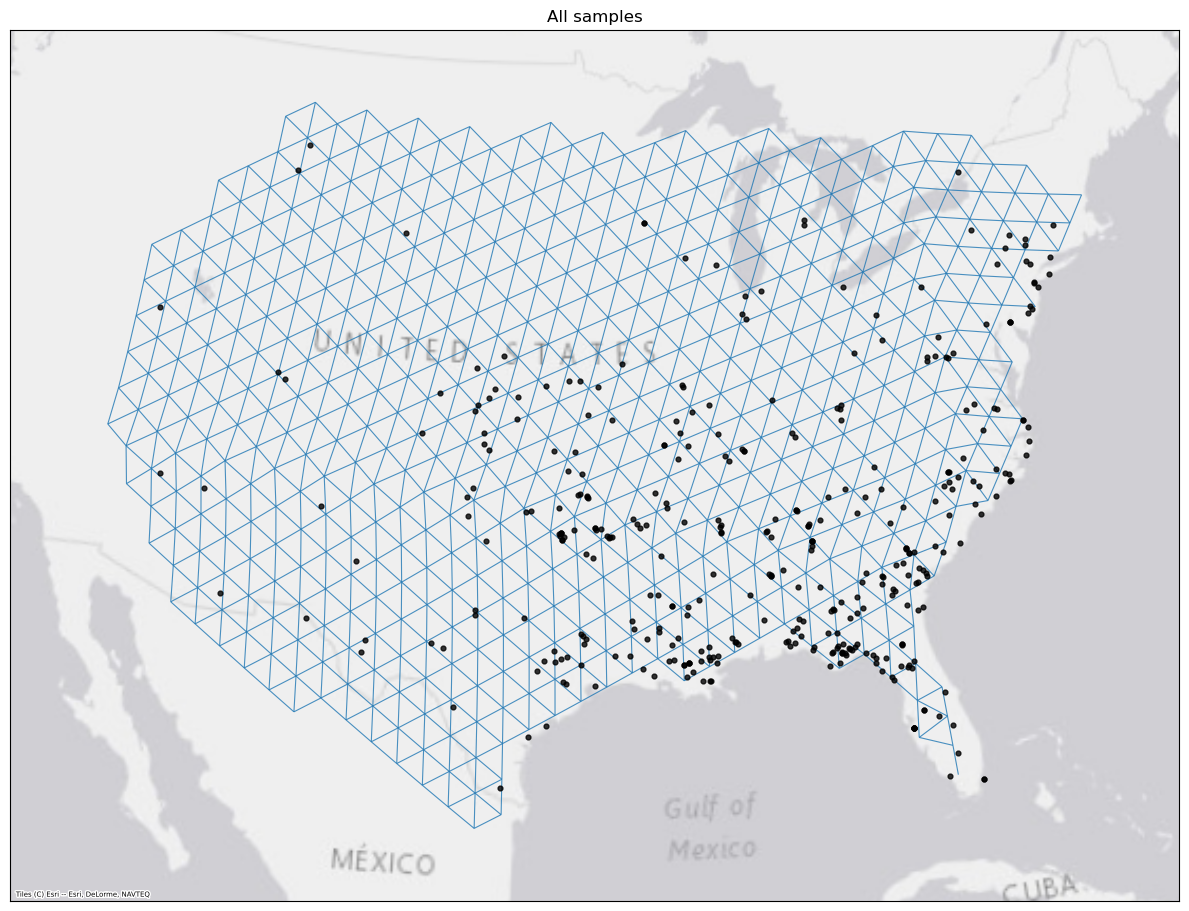

In [2]:
raster_paths = glob.glob('/Users/isaac/.cache/meadow/climate/bioclim/wc2.1/2.5m/bio/*.tif')

sp_list = load_species("./genotypes", coords_order="lonlat")

graphs, stats = build_species_graphs(
    sp_list,
    mesh_spacing_km=75,
    mask_coastline="terrestrial",
    buffer_km=100,
    support_decay_km=100,
    raster_paths=raster_paths,
    include_coord_midpoint=True,
)

_ = plot_samples(graphs, basemap_crs=PROJECT_TO, figsize=(12, 9))


In [3]:
import geopandas as gpd
from shapely.geometry import MultiPoint

# Save the bounding polygon and the graph structure
graph = graphs[0]
graph.export_gml("EasternSnake.gml")

# SpeciesGraph stores lat/lon; GeoJSON requires lon/lat.
boundary = MultiPoint(graph.node_coords[:, ::-1]).convex_hull

gpd.GeoDataFrame(
    {"name": [graph.name]},
    geometry=[boundary],
    crs="EPSG:4326",
).to_file(
    "EasternSnake_bounding_polygon.geojson",
    driver="GeoJSON",
)

In [5]:
model = train_model(
    graphs,
    epochs=1000,
    patience=100,
    min_delta=1e-6,
    lr=1e-2,
    edge_smoothing=0.1,
)

/var/folders/64/y4sy8ls95s54x9tt4ncj_d480000gn/T/ipykernel_26636/1231389365.py:1: UserWarning: Site holdout fell back to pair holdout for 8 species: Acontortrix, Dpunctatus, Fabacura, Ferytrogramma, Lgetula, Mflagellum, Pguttatus, Sdekayi. Site holdout requires at least min_val_pairs=50 pairs in both splits and at least 4 occupied sites. Lower min_val_pairs or adjust val_fraction, or explicitly set val_strategy='pair'. Pair holdout can share sites between training and validation.
  model = train_model(


epoch   25 loss 0.058753 val 0.007705
epoch   50 loss 0.052154 val 0.006692
epoch   75 loss 0.048417 val 0.006034
epoch  100 loss 0.045850 val 0.005687
epoch  125 loss 0.044227 val 0.005462
epoch  150 loss 0.042719 val 0.005211
epoch  175 loss 0.041854 val 0.005072
epoch  200 loss 0.052262 val 0.006141
epoch  225 loss 0.040800 val 0.004779
epoch  250 loss 0.039157 val 0.004578
epoch  275 loss 0.038478 val 0.004494
epoch  300 loss 0.038293 val 0.004465
epoch  325 loss 0.037783 val 0.004408
epoch  350 loss 0.037513 val 0.004372
epoch  375 loss 0.037488 val 0.004380
epoch  400 loss 0.037223 val 0.004258
epoch  425 loss 0.036856 val 0.004086
epoch  450 loss 0.052256 val 0.005697
epoch  475 loss 0.038471 val 0.004123
epoch  500 loss 0.035931 val 0.003713
epoch  525 loss 0.035091 val 0.003510
epoch  550 loss 0.034607 val 0.003424
epoch  575 loss 0.034258 val 0.003362
epoch  600 loss 0.033982 val 0.003312
epoch  625 loss 0.033875 val 0.003279
epoch  650 loss 0.033530 val 0.003227
epoch  675 l

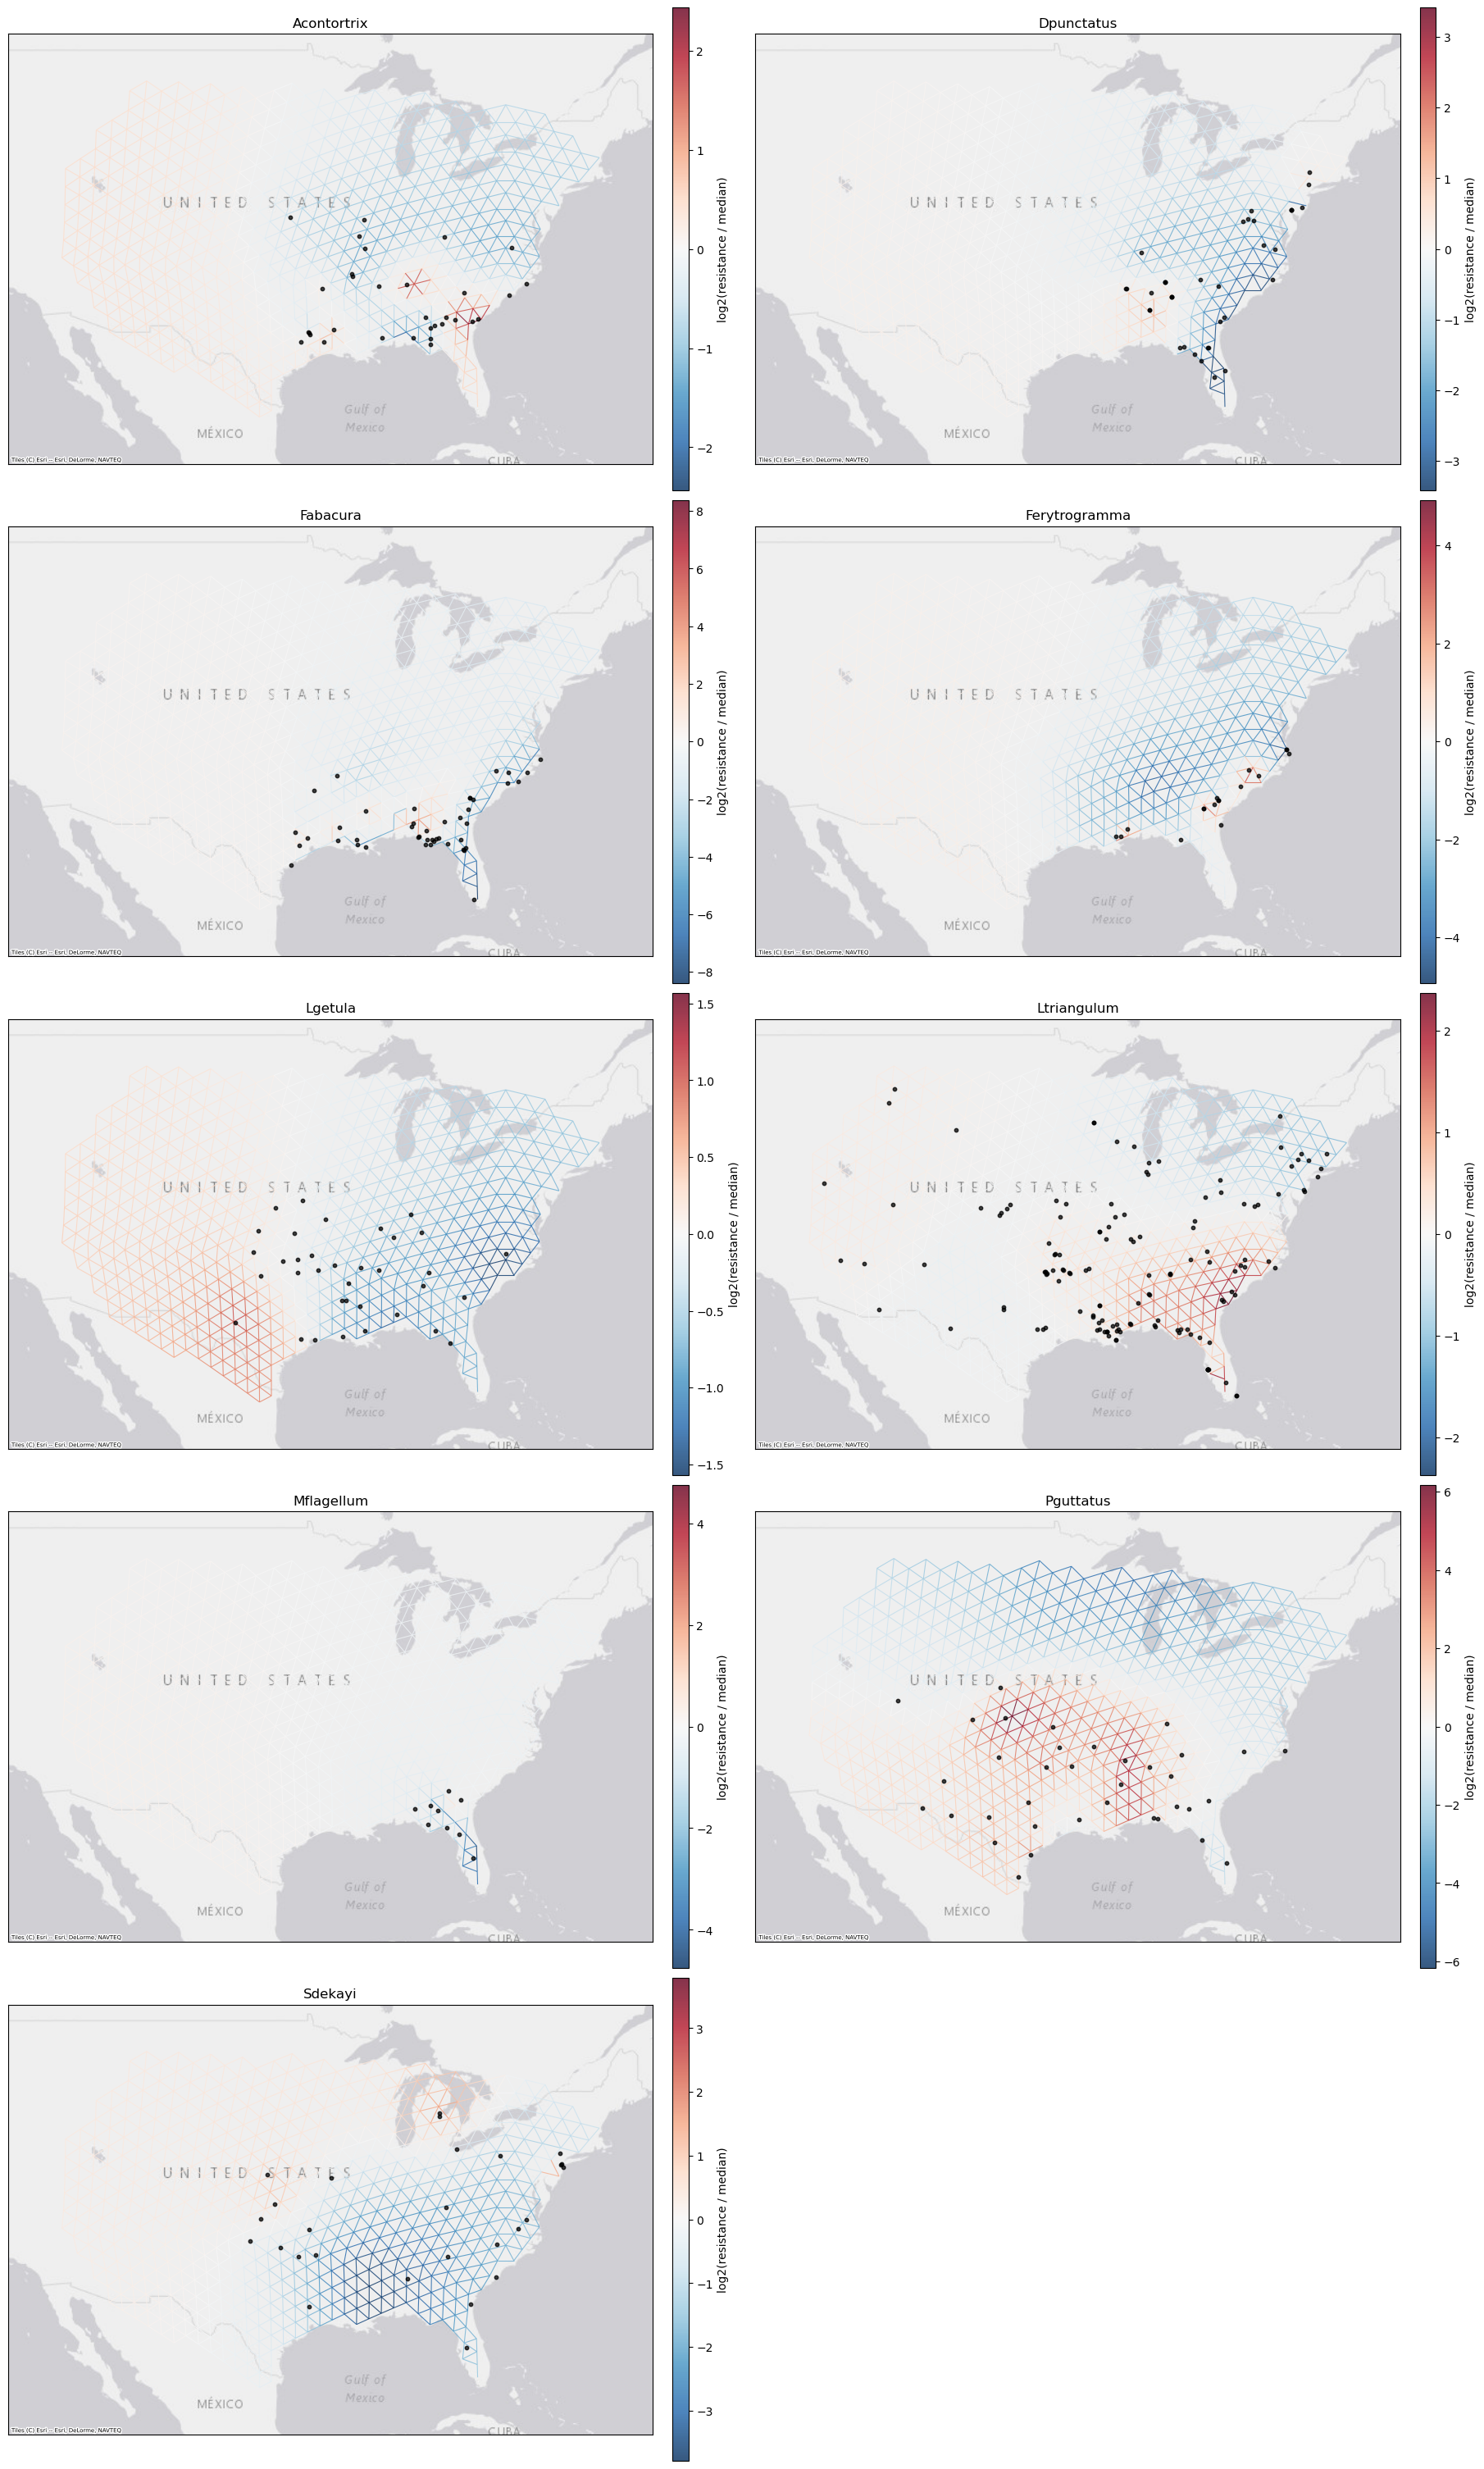

In [9]:
# Multi-species edge resistances (subplot grid)
_ = plot_multi_edge_resistance(
    sp_list,
    graphs,
    model,
    show_sites=True,
    explore=True,
    show_support_decay=False,
    support_decay_km=200,
    figsize=(9, 6),
    resistance_scale="log2_median",

)

<Axes: >

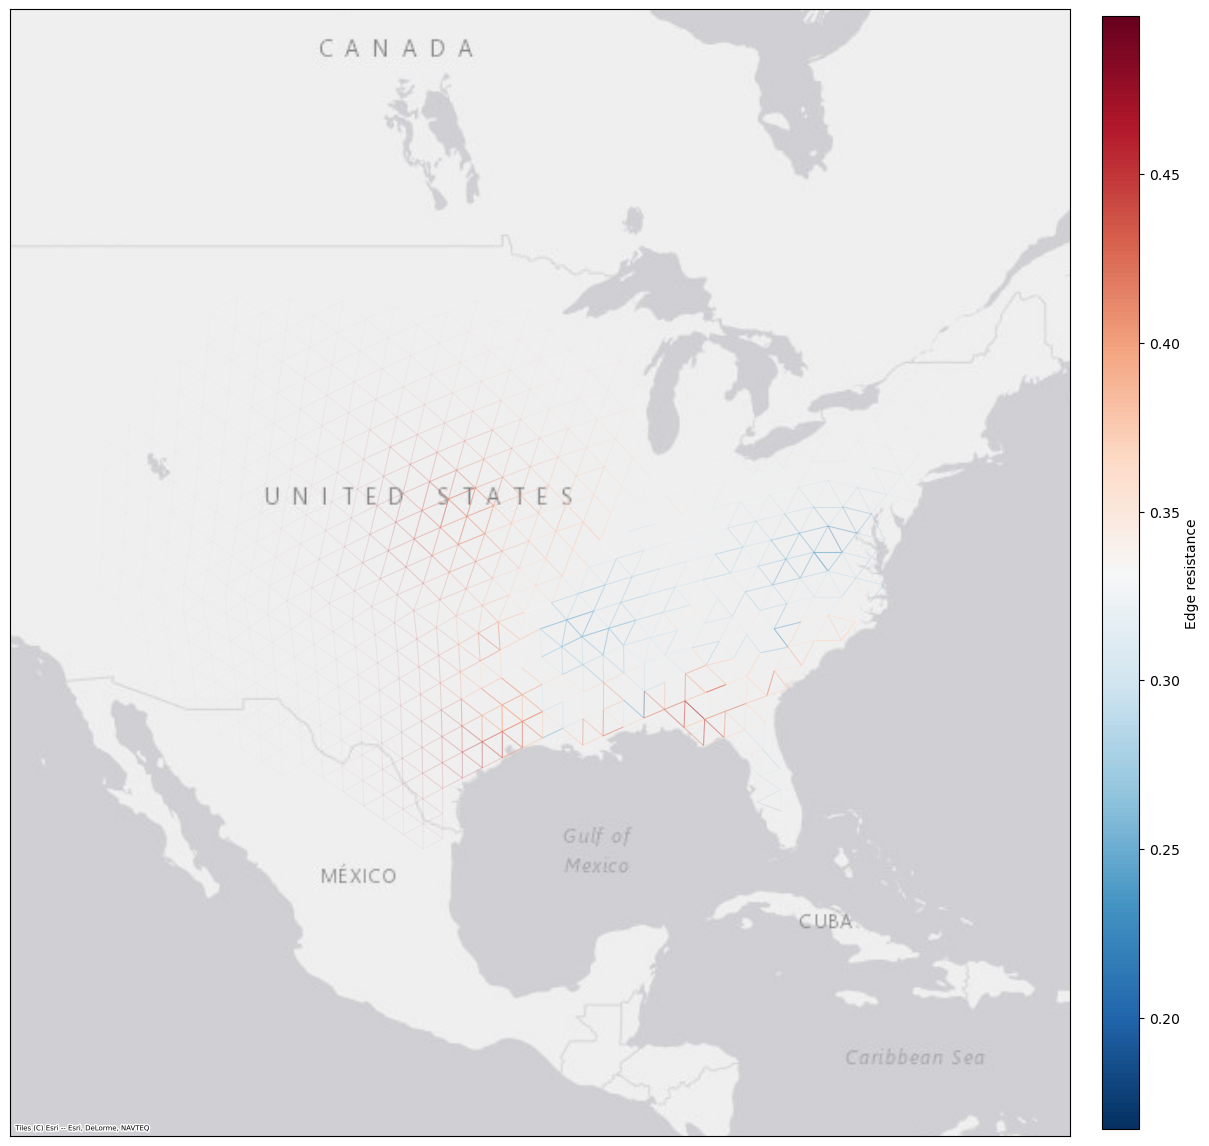

In [17]:
# Shared resistance surface (rasterized)
fig = plot_shared_resistance(
    sp_list,
    graphs,
    model,
    alpha=0.8,
    show_sites=False,
    figsize=(12,12),
    #outfile="Shared.png",
    show_support_decay=True,
    support_decay_km=250,
    #resistance_scale="log2_median",
)
fig[0]

In [11]:
%%time
from meadow.cv import choose_edge_smoothing_cv

res = choose_edge_smoothing_cv(graphs)

Task was destroyed but it is pending!
task: <Task pending name='Task-211' coro=<_async_in_context.<locals>.run_in_context() done, defined at /Users/isaac/miniconda3/envs/meadow/lib/python3.11/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-212' coro=<Kernel.shell_main() running at /Users/isaac/miniconda3/envs/meadow/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /Users/isaac/miniconda3/envs/meadow/lib/python3.11/site-packages/zmq/eventloop/zmqstream.py:563]>
Task was destroyed but it is pending!
task: <Task pending name='Task-212' coro=<Kernel.shell_main() running at /Users/isaac/miniconda3/envs/meadow/lib/python3.11/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>
Task was destroyed but it is pending!
task: <Task pending name='Task-229' coro=<_async_in_context.<locals>.run_in_context() done, defined at /Users/isaac/miniconda3/envs/meadow/lib/python3.11/sit

edge_smoothing=0.5 fold=3 run 40/40                                                                                     
Best edge_smoothing=0 (CV MSE=0.00656622, improvement=+49.0%)
edge_smoothing CV summary:
  edge_smoothing    model_mse    model_mse_std    constant_mse    improvement_percent    edge_cv    edge_q90_q10
----------------  -----------  ---------------  --------------  ---------------------  ---------  --------------
           0       0.00656622       0.00257683       0.0128744                48.9981  0.627747         80.4968
           0.1     0.0066008        0.00263158       0.0128744                48.7294  0.322917          7.96953
           0.075   0.00661471       0.00253517       0.0128744                48.6214  0.368933         13.3263
           0.2     0.00661757       0.00264924       0.0128744                48.5992  0.253055          6.10362
           0.05    0.00662526       0.0025019        0.0128744                48.5395  0.404806         12.9461
  